In [73]:
import math
import numpy as np
import matplotlib.pyplot as plt

## Step 1 : sample a simple Monte-Carlo Distribution

ising_JK defines two functions. energy allows to evaluate a Hamiltonian of parameters (J,K) on a Spin configuration, and delta-energy computes the energy variation from flipping one spin

In [74]:
def ising_JK(J: float = 1.0, K: float = 0.2):
    """H = -J sum_<ij> s_i s_j - K sum_plaquettes s_i s_j s_k s_l (periodic), as in the notebook.
    Returns (energy, delta_energy): total energy, and energy change when flipping s[i, j]."""
    def energy(Spins):
        r0, r1 = np.roll(Spins, -1, axis=0), np.roll(Spins, -1, axis=1)
        return float(-J * np.sum(Spins * (r0 + r1)) - K * np.sum(Spins * r0 * r1 * np.roll(r0, -1, axis=1)))

    def delta_energy(Spins, i, j):
        L = Spins.shape[0]; ip, jp = (i + 1) % L, (j + 1) % L
        dJ = Spins[i-1, j] + Spins[ip, j] + Spins[i, j-1] + Spins[i, jp]
        dK = (Spins[i-1, j-1]*Spins[i-1, j]*Spins[i, j-1] + Spins[i-1, j]*Spins[i-1, jp]*Spins[i, jp]
              + Spins[i, j-1]*Spins[ip, j-1]*Spins[ip, j] + Spins[i, jp]*Spins[ip, j]*Spins[ip, jp])
        return float(2 * Spins[i, j] * (J * dJ + K * dK))
    return energy, delta_energy

We use these functions to generate the Metropolis-Hastings configurations we will latter use to train H_eff

In [75]:
def metropolis_hastings(energy, n_configs: int, L: int, T: float, rng: np.random.Generator,
                        delta_energy=None, n_warmup: int = 1000, length_cycle: int | None = None):
    """Step (i) of SLMC: local-update Metropolis-Hastings simulation with the original Hamiltonian H.

    energy(Spins)            -> total energy of the L x L spin array Spins (entries +-1), i.e. H.
    delta_energy(Spins,i,j)  -> energy change if Spins[i,j] is flipped (fast, O(1))
    n_warmup             -> sweeps (L*L moves) discarded to reach equilibrium.
    length_cycle         -> single-spin moves between two stored configurations (default: one sweep, L*L).
    Returns configs (n_configs, L, L) of +-1 and their energies (n_configs,).
    """
    beta = 1.0 / T
    length_cycle = L * L if length_cycle is None else length_cycle
    Spins = rng.choice([-1, 1], size=(L, L))
    E = energy(Spins)

    def run(n_moves):
        nonlocal E
        sites = rng.integers(L, size=(n_moves, 2)).tolist()   # all random numbers drawn at once
        uniforms = rng.random(n_moves).tolist()
        for (i, j), u in zip(sites, uniforms):
            if delta_energy is not None:
                dE = delta_energy(Spins, i, j)
            else:                                              # generic H: flip, measure, flip back
                Spins[i, j] *= -1
                dE = energy(Spins) - E
                Spins[i, j] *= -1
            if dE <= 0 or u < math.exp(-beta * dE):            # accept with min(1, e^{-beta dE})
                Spins[i, j] *= -1
                E += dE

    run(n_warmup * L * L)
    configs = np.empty((n_configs, L, L), dtype=np.int8)
    energies = np.empty(n_configs)
    for n in range(n_configs):
        run(length_cycle)
        configs[n], energies[n] = Spins, E
    assert abs(E - energy(Spins)) < 1e-6 * max(1, abs(E)), "the running energy drifted"
    return configs, energies

Example part 1 : generation of the configurations 

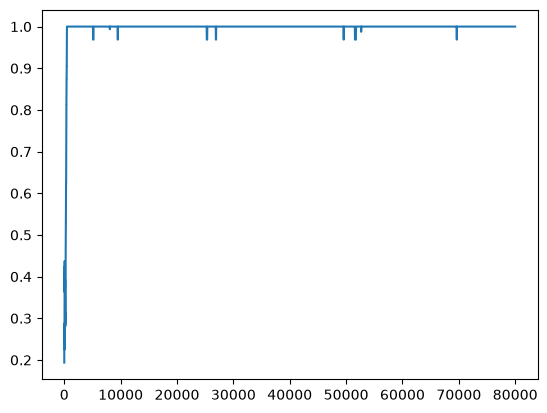

In [76]:
J=1
K=0.2

rng = np.random.default_rng(42)
n_configs=80_000

L=8
T=1

n_warmup = 1000

energy, delta_energy = ising_JK(J,K)
configs_train, _ = metropolis_hastings(energy, n_configs, L, T=1, rng=rng, delta_energy=delta_energy, n_warmup=0, length_cycle=1)

Times = [k for k in range(n_configs - 5)]
# Mag = [np.mean(configs[k], axis=(0,1)) for k in range(n_configs)]
Mag = [np.mean(configs_train[k:k+5], axis=(0,1,2)) for k in range(n_configs - 5)]

plt.plot(Times, Mag)
plt.show()

In [77]:
configs_ini, energies = metropolis_hastings(energy, n_configs, L, T, rng, delta_energy, n_warmup)

## Step 2 : we train H_eff on those configs

we calculate the n_max first NN spin-spin correlations : 

In [78]:
def correlations(configs: np.ndarray, n_max: int = 2) -> np.ndarray:
    """C_n^a = sum over the n-th nearest-neighbor pairs <ij>_n of S_i S_j, for each configuration a.

    configs: (n_configs, L, L) array of +-1 
    n_max : max distance of correlations calculated 
    Returns C of shape (n_configs, n_max): column n-1 holds C_n (n=1: NN, 2: next-NN diagonal, 3: distance 2, ...).
    Each pair is counted once. Needs L > 2*sqrt(d_n^2) so that no pair is counted twice by periodicity.
    """
    s = np.asarray(configs)
    R = n_max
    # all displacements (dx, dy), grouped by squared distance -> shells 1, 2, 3, ... of neighbors
    shells = sorted({dx*dx + dy*dy for dx in range(-R, R+1) for dy in range(-R, R+1)} - {0})[:n_max]
    CaN = np.empty((len(s), n_max))
    for n, d2 in enumerate(shells):
        # one of the two opposite displacements, so that every pair appears once
        disp = [(dx, dy) for dx in range(-R, R+1) for dy in range(-R, R+1)
                if dx*dx + dy*dy == d2 and (dx > 0 or (dx == 0 and dy > 0))]
        CaN[:, n] = sum((s * np.roll(s, (-dx, -dy), axis=(1, 2))).sum(axis=(1, 2)) for dx, dy in disp)
    return CaN

we train H_eff with those correlations, and configurations energies. We evaluate the difference between the real energy and the one approximated by H_eff

In [79]:
def learningH(CaN, Ea) -> "list[float]":
    """
    learning Heff based on the CaN and Ea values with least square method
    Expecting Ea to be a matrix of shape (n, 1) and CaN to be a matrix of shape (n, m)
    Return a list of Heff values, where the first value is the intercept and the rest are the coefficients for each feature in CaN. (m, 1)
    """
    ones = np.ones((CaN.shape[0], 1))
    A = np.hstack((ones, -CaN))
    # Perform least squares fit
    H = np.linalg.lstsq(A, Ea, rcond=None)[0]
    return H.flatten().tolist()


def meanDifferenceH(CaN, Ea) -> float:
    """
    Calculate the mean difference between the predicted Ea and the actual Ea
    Expecting Ea to be a matrix of shape (n, 1) and CaN to be a matrix of shape (n, m)
    """
    H = learningH(CaN, Ea)
    ones = np.ones((CaN.shape[0], 1))
    A = np.hstack((ones, -CaN))
    Ea_predicted = A @ H
    difference = np.sum(np.abs(Ea - Ea_predicted))
    return difference/CaN.shape[0]

Example part 2 :training of H_eff

In [80]:
Cn=correlations(configs_ini, n_max=4)
H_eff=learningH(Cn,energies)
print(H_eff)
print(meanDifferenceH(Cn,energies))
J_eff=H_eff[1]
K_eff=0 #no K in H_eff

[12.799999999998896, 1.3999999999999833, -0.04000000001106596, -8.881784197001252e-16, -0.07999999999446805]
1.3920955055368723e-12


## Step 3 : wolff sampling using H_eff

we define a wolff function that return a flipped spin cluster


we now have H_eff, and want to use it to sample configurations with the wolff algorithms 

In [81]:
def neighbor(spin : tuple, L): #return the neighbors of site [i,j]
    i,j=spin[0],spin[1]
    return [((i+1)%L, j), ((i-1)%L, j), (i, (j+1)%L), (i, (j-1)%L)]

def wolff(Spins : np.ndarray, J : float, beta : float ): 
    #returns a wolff cluster around a random site [i,j]. All the spins of the cluster have been flipped
    L=len(Spins)
    p_add=1-np.exp(-2*beta*J)
    cluster=[]
    i, j = rng.integers(0, L, size=2)
    s0=Spins[i,j]
    Spins[i, j] = -s0
    pile=[(i,j)]

    while len(pile)!=0:
        spin=pile.pop()
        cluster.append(spin)
        neighbors=neighbor(spin,L)
        for nb in neighbors:
            if s0==Spins[nb]:
                r = rng.random()
                if r<=p_add:
                    pile.append(nb)
                    Spins[nb] = -s0
    
    return cluster

we enrich the ising_JK function so it can calculate energy variation when a whole cluster is flipped

In [82]:
def ising_JK_enriched(J: float = 1.0, K: float = 0.2):
    """H = -J sum_<ij> s_i s_j - K sum_plaquettes s_i s_j s_k s_l (periodic), as in the notebook.
    Returns (energy, delta_energy): total energy, and energy change when flipping s[i, j]."""
    def energy(s):
        r0, r1 = np.roll(s, -1, axis=0), np.roll(s, -1, axis=1)
        return float(-J * np.sum(s * (r0 + r1)) - K * np.sum(s * r0 * r1 * np.roll(r0, -1, axis=1)))

    def delta_energy(s, i, j):
        L = s.shape[0]; ip, jp = (i + 1) % L, (j + 1) % L
        dJ = s[i-1, j] + s[ip, j] + s[i, j-1] + s[i, jp]
        dK = (s[i-1, j-1]*s[i-1, j]*s[i, j-1] + s[i-1, j]*s[i-1, jp]*s[i, jp]
              + s[i, j-1]*s[ip, j-1]*s[ip, j] + s[i, jp]*s[ip, j]*s[ip, jp])
        return float(2 * s[i, j] * (J * dJ + K * dK))
    
    def delta_energy_cluster(Spins, cluster):
        """Energy change when flipping all spins in `mask` (bool (L, L)), computed before the flip.
        A term of H changes iff it contains an odd number of flipped spins; it then changes sign:
        dE = 2 * sum(coupling * product of its spins), over those terms only."""
        r0, r1 = np.roll(Spins, -1, axis=0), np.roll(Spins, -1, axis=1)
        m0, m1 = np.roll(cluster, -1, axis=0), np.roll(cluster, -1, axis=1)
        dE_J = 2 * J * ((Spins * r0)[cluster ^ m0].sum() + (Spins * r1)[cluster ^ m1].sum())          # bonds on the cluster boundary
        plaquette = Spins * r0 * r1 * np.roll(r0, -1, axis=1)
        dE_K = 2 * K * plaquette[cluster ^ m0 ^ m1 ^ np.roll(m0, -1, axis=1)].sum()        # plaquettes cut an odd number of times
        return float(dE_J + dE_K)
    return energy, delta_energy_cluster

we now sample Monte-Carlo configurations 

In [83]:
def metropolis_hastings_wolff(energy_H, delta_energy_H, delta_energy_Heff, J_eff,
                              n_configs, L, T, rng, n_warmup=1000, length_cycle=1):
    """SLMC simulation: Wolff clusters built with H_eff = -J_eff * sum_<ij> s_i s_j, accepted with Eq. 3.
    delta_energy_H(s, mask), delta_energy_Heff(s, mask) -> energy change if the cluster `mask` is flipped.
    n_warmup, length_cycle count cluster flips."""
    beta = 1.0 / T
    Spins = rng.choice([-1, 1], size=(L, L))

    def to_mask(cluster):
        c = np.asarray(cluster)
        if c.dtype == bool:
            return c
        mask = np.zeros((L, L), dtype=bool); mask[c[:, 0], c[:, 1]] = True
        return mask

    def run(n_moves):
        for _ in range(n_moves):
            mask = to_mask(wolff(Spins, J_eff, beta))
            dE = -(delta_energy_H(Spins, mask) - delta_energy_Heff(Spins, mask)) #- sign cause wolff flipped the cluster
            if dE <= 0 or rng.random() < math.exp(-beta * dE):
                Spins[mask] *= 1 #do nothing cause wolff already flipped the cluster                      # in place, no copy needed
            else :
                Spins[mask] *= -1 #flip it back if config not accepted
    run(n_warmup)
    configs = np.empty((n_configs, L, L), dtype=np.int8)
    energies = np.empty(n_configs)
    for n in range(n_configs):
        run(length_cycle)
        configs[n], energies[n] = Spins, energy_H(Spins)
    return configs, energies

Example part 3 : sample configurations 

In [84]:
energy_H, delta_energy_H = ising_JK_enriched(J,K)
energy_H_eff, delta_energy_H_eff = ising_JK_enriched(J_eff,K_eff)
configs_wolff, energies = metropolis_hastings_wolff(energy_H, delta_energy_H, delta_energy_H_eff, J_eff,n_configs, L, T, rng, n_warmup=1000, length_cycle=1)

We are now going to calculate the correlation time and plot it. Here we estimate :

\begin{equation}
  \mathcal{C}(t) = \langle m(t) \, m(0) \rangle - \langle m \rangle^2
\end{equation}

by :

\begin{equation}
  \mathcal{C}(t) \simeq \frac{1}{n - t} \sum_{s=0}^{n-t-1} (m_{s+t} - \bar{m})(m_s - \bar{m})
\end{equation}

as seen in class.

In [85]:
import numpy as np
from scipy.optimize import curve_fit

def autocorrelation(x: np.ndarray, t_max: int) -> np.ndarray:
    """Normalized autocorrelation function C(t) / C(0) of the time series x, for t = 0, ..., t_max - 1."""
    x = x - x.mean()
    n = len(x)
    corr = np.array([np.dot(x[: n - t], x[t:]) / (n - t) for t in range(t_max)])
    return corr / corr[0]

def autocorrelation_time(corr: np.ndarray, threshold: float = 0.1) -> float:
    """Fit exp(-t / tau) to the autocorrelation function, as long as it stays above `threshold`."""
    below = np.flatnonzero(corr < threshold)
    n_fit = max(below[0] if len(below) else len(corr), 3)
    t = np.arange(n_fit)
    (tau,), _ = curve_fit(lambda t, tau: np.exp(-t / tau), t, corr[:n_fit], p0=(1.0,))
    return tau

C:\Users\mattm\AppData\Local\Temp\ipykernel_14368\1116299817.py:9: RuntimeWarning: invalid value encountered in divide
  return corr / corr[0]


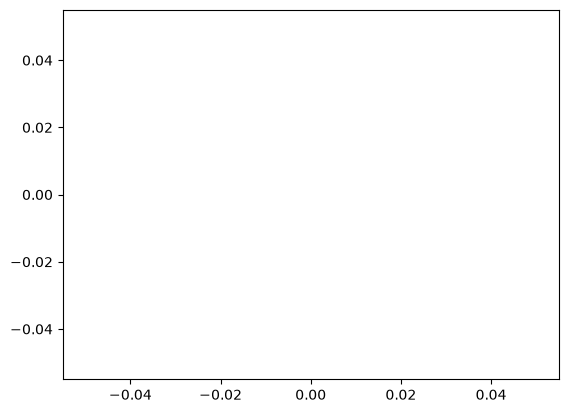

ValueError: array must not contain infs or NaNs

In [86]:
import matplotlib.pyplot as plt

n_max = 5

corr = autocorrelation(np.abs(np.mean(configs_ini[:n_max,:,:], axis=(1,2))), n_max)
T = [k for k in range(n_max)]
plt.plot(T, corr)
plt.show()

print(autocorrelation_time(corr))